# Challenge statistics distributions

Load challenge YAML(s) and plot distributions for **end_uri_statistics** and **start_uri_statistics** (in_degree, out_degree, reversed_neighborhood_size).

In [31]:
import yaml
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Path to challenge file(s); use one or more YAMLs (e.g. full challenge or splits)
CHALLENGE_PATHS = [
    Path("../dbpedia_challenge.yaml"),
    Path("../dbpedia_challenge_2.yaml"),
    Path("../dbpedia_challenge_3.yaml"),
    Path("../dbpedia_challenge_4.yaml"),
    Path("../dbpedia_challenge_5.yaml"),
    # Path("../splits/split_dbpedia_challenge_1_of_4.yaml"),
]

def load_questions_by_id(paths):
    """Load all questions from YAMLs and return dict id -> full question dict."""
    by_id = {}
    for path in paths:
        with open(path, "r", encoding="utf-8") as f:
            data = yaml.safe_load(f)
        for q in data.get("questions", []):
            if isinstance(q, dict) and "id" in q:
                by_id[q["id"]] = q
    return by_id

questions_by_id = load_questions_by_id(CHALLENGE_PATHS)

In [2]:
def load_statistics(path: Path) -> list[dict]:
    """Load challenge YAML and return list of {id, end_*, start_*} per question."""
    with open(path, "r", encoding="utf-8") as f:
        data = yaml.safe_load(f)
    questions = data.get("questions", [])
    rows = []
    for q in questions:
        if not isinstance(q, dict):
            continue
        stats = q.get("statistics") or {}
        end_s = stats.get("end_uri_statistics") or {}
        start_s = stats.get("start_uri_statistics") or {}
        rows.append({
            "id": q.get("id", ""),
            "source": path.name,
            "end_in_degree": end_s.get("in_degree"),
            "end_out_degree": end_s.get("out_degree"),
            "end_reversed_neighborhood_size": end_s.get("reversed_neighborhood_size"),
            "start_in_degree": start_s.get("in_degree"),
            "start_out_degree": start_s.get("out_degree"),
            "start_reversed_neighborhood_size": start_s.get("reversed_neighborhood_size"),
        })
    return rows

all_rows = []
for p in CHALLENGE_PATHS:
    if not p.exists():
        print(f"Skip (not found): {p}")
        continue
    all_rows.extend(load_statistics(p))

df = pd.DataFrame(all_rows)
print(f"Loaded {len(df)} tasks from {len(CHALLENGE_PATHS)} file(s).")
df.head()

Loaded 901 tasks from 5 file(s).


,id,source,end_in_degree,end_out_degree,end_reversed_neighborhood_size,start_in_degree,start_out_degree,start_reversed_neighborhood_size
0,W. B. Henderson_Siege of Breteuil,dbpedia_challenge.yaml,5,77,6237,11,65,10423
1,W. B. Henderson_Shock therapy (economics),dbpedia_challenge.yaml,97,99,12096,11,65,10423
2,Lynne Cohen_Kangchenjunga,dbpedia_challenge.yaml,320,212,17914,18,70,8379
3,Lynne Cohen_Mount Ararat,dbpedia_challenge.yaml,330,339,30585,18,70,8379
4,Mathilde Mann_British Forces casualties in Afg...,dbpedia_challenge.yaml,0,0,1,1,35,6714


In [10]:
# Bins: [0, 1000), [1000, 2000), [2000, 3000), ...
step = 1000
col = df["end_reversed_neighborhood_size"].dropna()
bins = range(0, int(col.max()) + step + 1, step)  # 0, 1000, 2000, ... up to max

df["end_reversed_group_1k"] = pd.cut(
    df["end_reversed_neighborhood_size"],
    bins=bins,
    labels=False,           # group 0, 1, 2, ... (or omit for interval labels)
    include_lowest=True,
)

In [22]:
subset_df = df[df["end_reversed_group_1k"] <= 30]

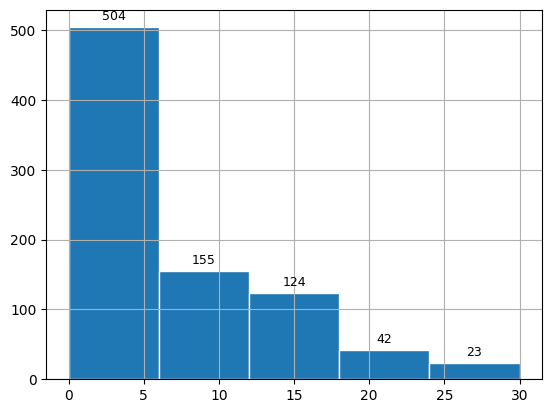

In [25]:
import matplotlib.pyplot as plt
import numpy as np
ax = subset_df["end_reversed_group_1k"].hist(bins=5, edgecolor="white")
# hist() returns an array of axes; use ax[0] if it's a single subplot
axes = ax if isinstance(ax, np.ndarray) else [ax]
for ax in axes:
    for bar in ax.patches:
        h = bar.get_height()
        if h > 0:
            ax.annotate(f"{int(h)}", (bar.get_x() + bar.get_width()/2, h),
                        xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9)
plt.show()

In [29]:
BINS = 5
subset_df["end_reversed_bin5"], bin_edges = pd.cut(
    subset_df["end_reversed_neighborhood_size"],
    bins=BINS,
    labels=False,      # 0, 1, 2, 3, 4 (use False for integers)
    retbins=True,
    include_lowest=True,
    duplicates="drop",
)

# Randomly pick from the subset_df of each bin until we have a equal split of 100 tasks
TASK_COUNT = 100
tasks = {}


for bin_idx in range(BINS):
    bin_df = subset_df[subset_df["end_reversed_bin5"] == bin_idx]
    tasks[bin_idx] = bin_df.sample(TASK_COUNT//BINS).to_dict(orient="records")
           
tasks

{0: [{'id': 'Decorospora_Hymenobia',
   'source': 'dbpedia_challenge_4.yaml',
   'end_in_degree': 2,
   'end_out_degree': 10,
   'end_reversed_neighborhood_size': 1995,
   'start_in_degree': 3,
   'start_out_degree': 11,
   'start_reversed_neighborhood_size': 701,
   'end_reversed_group_1k': 1,
   'end_reversed_bin5': 0},
  {'id': 'PDP–Laban (2021)_Save the Newchurch Guinea Pigs',
   'source': 'dbpedia_challenge_3.yaml',
   'end_in_degree': 15,
   'end_out_degree': 36,
   'end_reversed_neighborhood_size': 3957,
   'start_in_degree': 0,
   'start_out_degree': 0,
   'start_reversed_neighborhood_size': 1,
   'end_reversed_group_1k': 3,
   'end_reversed_bin5': 0},
  {'id': 'Pulau Indah Expressway_Afif Bahardin',
   'source': 'dbpedia_challenge_4.yaml',
   'end_in_degree': 29,
   'end_out_degree': 44,
   'end_reversed_neighborhood_size': 4891,
   'start_in_degree': 13,
   'start_out_degree': 29,
   'start_reversed_neighborhood_size': 1429,
   'end_reversed_group_1k': 4,
   'end_reversed_bin

In [34]:
# Flatten tasks into one list of records
sampled_records = []
for bin_idx in range(BINS):
    sampled_records.extend(tasks[bin_idx])

# Get full question dicts in order (preserve bin order if you care)
sampled_questions = []
for bin_idx in range(BINS):
    for r in tasks[bin_idx]:
        qid = r.get("id")
        if qid not in questions_by_id:
            print(f"Missing id: {qid}")
            continue
        q = questions_by_id[qid].copy()   # copy so we don't mutate the original
        q["task_complexity"] = bin_idx    # or "complexity_bin" if you prefer
        sampled_questions.append(q)

# Load dataset header from first file
with open(CHALLENGE_PATHS[0], "r", encoding="utf-8") as f:
    template = yaml.safe_load(f)

out = {
    "dataset": template.get("dataset", {"id": "", "prefix": "dbpedia-challenge"}),
    "questions": sampled_questions,
}

out_path = Path("../dbpedia_challenge_sampled.yaml")
with open(out_path, "w", encoding="utf-8") as f:
    yaml.safe_dump(out, f, sort_keys=False, default_flow_style=False, allow_unicode=True)

print(f"Wrote {len(sampled_questions)} questions to {out_path}")

Wrote 100 questions to ../dbpedia_challenge_sampled.yaml


## Distributions: end_uri_statistics vs start_uri_statistics

Histograms and KDE for each metric, comparing **end** (end URI of the path) and **start** (start URI).

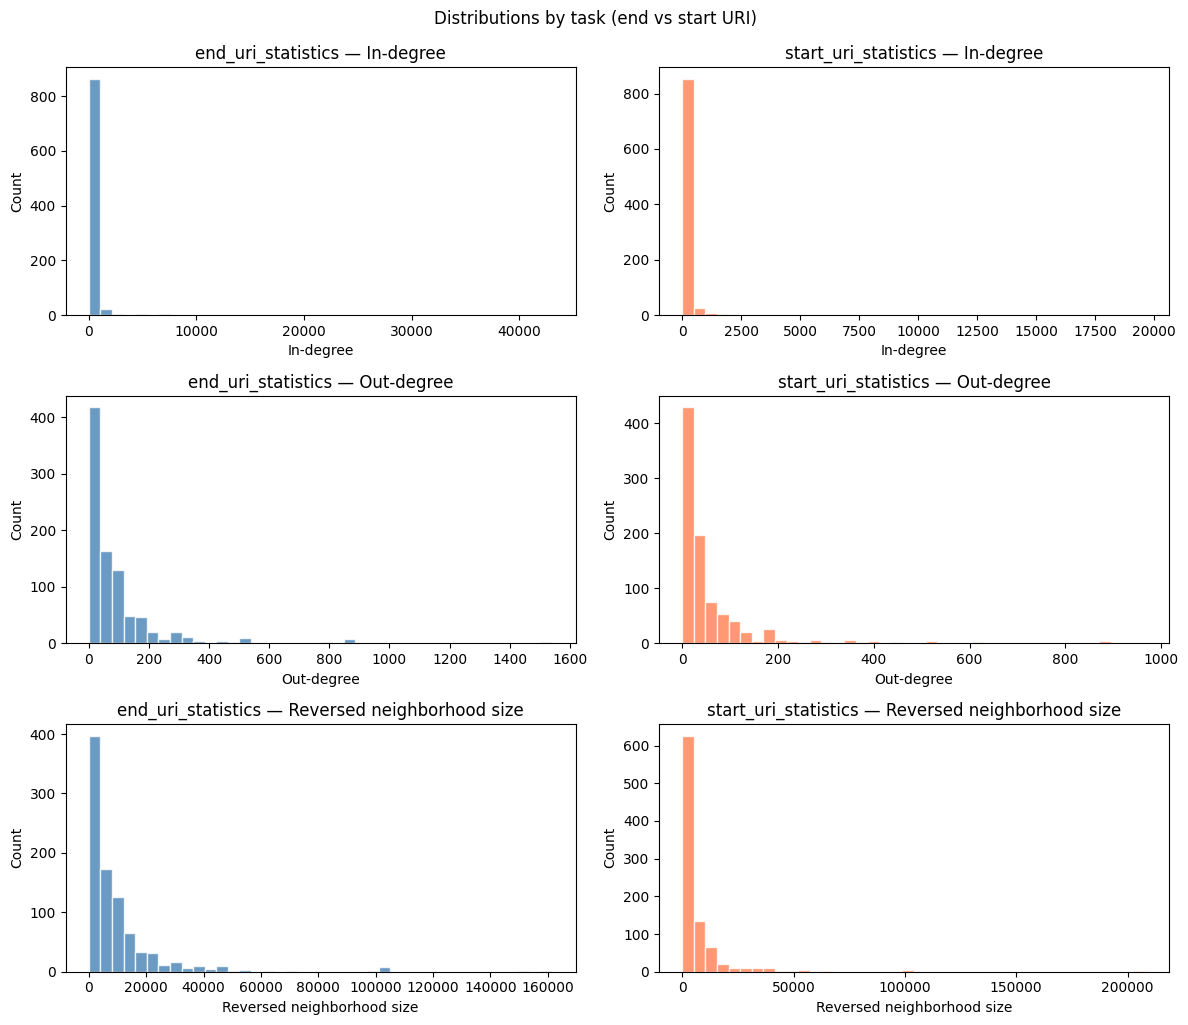

In [9]:
fig, axes = plt.subplots(3, 2, figsize=(12, 10))

metrics = [
    ("in_degree", "In-degree"),
    ("out_degree", "Out-degree"),
    ("reversed_neighborhood_size", "Reversed neighborhood size"),
]
for i, (key, label) in enumerate(metrics):
    end_col = f"end_{key}"
    start_col = f"start_{key}"
    # End URI
    axes[i, 0].hist(df[end_col].dropna(), bins=40, color="steelblue", alpha=0.8, edgecolor="white")
    axes[i, 0].set_title(f"end_uri_statistics — {label}")
    axes[i, 0].set_xlabel(label)
    axes[i, 0].set_ylabel("Count")
    # Start URI
    axes[i, 1].hist(df[start_col].dropna(), bins=40, color="coral", alpha=0.8, edgecolor="white")
    axes[i, 1].set_title(f"start_uri_statistics — {label}")
    axes[i, 1].set_xlabel(label)
    axes[i, 1].set_ylabel("Count")

plt.tight_layout()
plt.suptitle("Distributions by task (end vs start URI)", y=1.02, fontsize=12)
plt.show()